Available IDs:
1. 00576224
2. 007bbfb7
3. 009d5c81
4. 00d62c1b
5. 00dbd492
6. 017c7c7b
7. 025d127b
8. 03560426
9. 045e512c
10. 0520fde7
11. 05269061
12. 05a7bcf2
13. 05f2a901
14. 0607ce86
15. 0692e18c
16. 06df4c85
17. 070dd51e
18. 08ed6ac7
19. 09629e4f
20. 0962bcdd
21. 09c534e7
22. 0a1d4ef5
23. 0a2355a6
24. 0a938d79
25. 0b148d64
26. 0b17323b
27. 0bb8deee
28. 0becf7df
29. 0c786b71
30. 0c9aba6e
31. 0ca9ddb6
32. 0d3d703e
33. 0d87d2a6
34. 0e206a2e
35. 0e671a1a
36. 0f63c0b9
37. 103eff5b
38. 10fcaaa3
39. 11852cab
40. 1190bc91
41. 1190e5a7
42. 11dc524f
43. 11e1fe23
44. 12422b43
45. 12997ef3
46. 12eac192
47. 13713586
48. 137eaa0f
49. 137f0df0
50. 13f06aa5
51. 140c817e
52. 14754a24
53. 1478ab18
54. 14b8e18c
55. 150deff5
56. 15113be4
57. 15660dd6
58. 15663ba9
59. 15696249
60. 17829a00
61. 178fcbfb
62. 17b80ad2
63. 17b866bd
64. 17cae0c1
65. 18286ef8
66. 182e5d0f
67. 18419cfa
68. 18447a8d
69. 184a9768
70. 195ba7dc
71. 1990f7a8
72. 19bb5feb
73. 1a07d186
74. 1a244afd
75. 1a2e2828
76. 1a6449f1
77. 1a

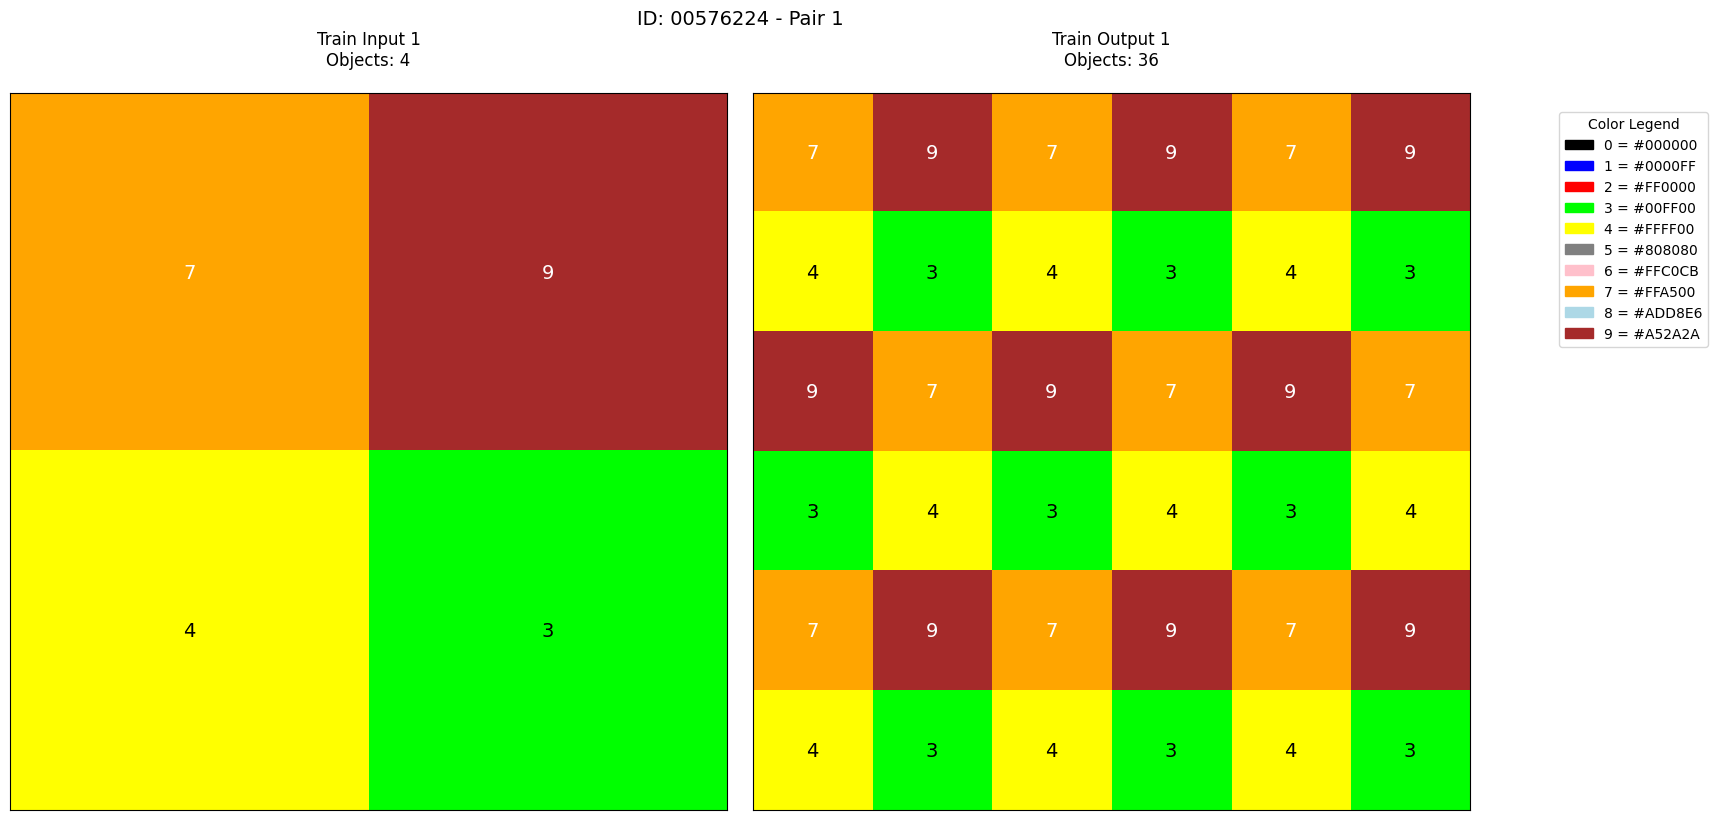


=== Analysis for Pair 1 ===

=== Movement Analysis ===
Object 1: No movement detected
Object 2: Movement detected - shifted by 0.0 rows, -1.0 columns (color changed from 9 to 7)
Object 3: Movement detected - shifted by -1.0 rows, 0.0 columns (color changed from 4 to 7)
Object 4: Movement detected - shifted by -1.0 rows, -1.0 columns (color changed from 3 to 7)

=== Scale Analysis ===
Input dimensions: 2 rows × 2 columns
Output dimensions: 6 rows × 6 columns
Row scaling (output/input): 3.00 (3)
Column scaling (output/input): 3.00 (3)
Uniform expansion by factor 3
Integer scaling factors

=== Color Change Analysis ===
Grids have different dimensions - cannot perform direct color change analysis

=== Enclosed Object Analysis ===
No enclosed objects detected

=== Enclosed Object Analysis ===
No enclosed objects detected

=== Input Shape Detection ===
Object 1 (color 7): single pixel 1×1, area=1
Object 2 (color 9): single pixel 1×1, area=1
Object 3 (color 4): single pixel 1×1, area=1
Objec

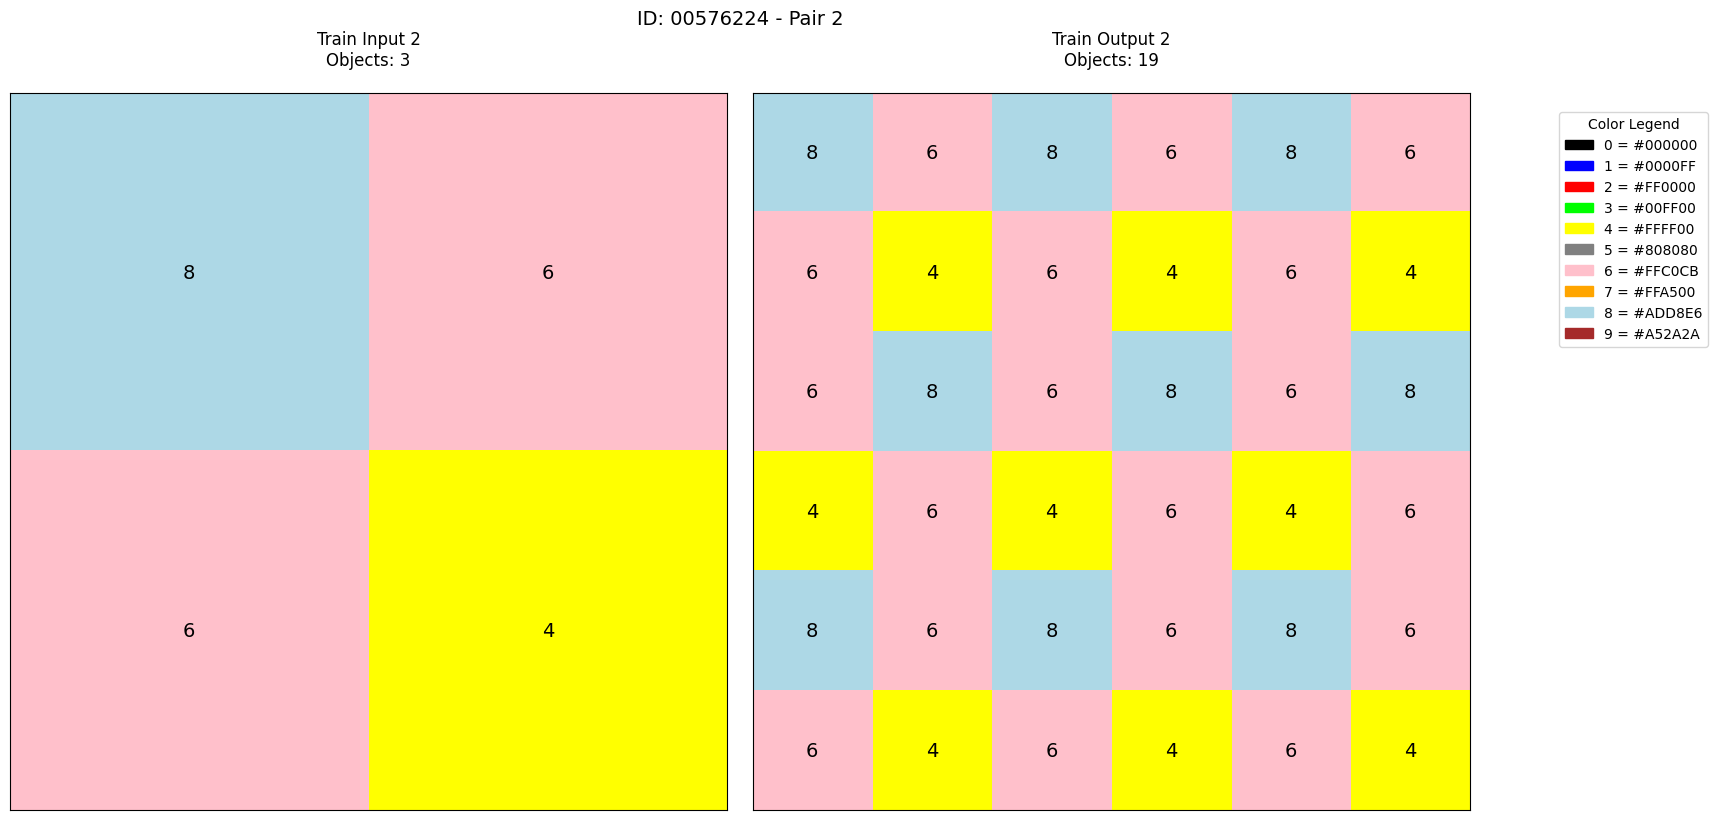


=== Analysis for Pair 2 ===

=== Movement Analysis ===
Object 1: No movement detected
Object 2: No similar shaped object detected in output
Object 3: Movement detected - shifted by -1.0 rows, -1.0 columns (color changed from 4 to 8)

=== Scale Analysis ===
Input dimensions: 2 rows × 2 columns
Output dimensions: 6 rows × 6 columns
Row scaling (output/input): 3.00 (3)
Column scaling (output/input): 3.00 (3)
Uniform expansion by factor 3
Integer scaling factors

=== Color Change Analysis ===
Grids have different dimensions - cannot perform direct color change analysis

=== Enclosed Object Analysis ===
No enclosed objects detected

=== Enclosed Object Analysis ===
No enclosed objects detected

=== Input Shape Detection ===
Object 1 (color 8): single pixel 1×1, area=1
Object 2 (color 6): triangle 2×2, area=2
Object 3 (color 4): single pixel 1×1, area=1

=== Output Shape Detection ===
Object 1 (color 8): single pixel 1×1, area=1
Object 2 (color 6): unknown 6×6, area=18
Object 3 (color 8): s

In [7]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.colors import ListedColormap
import json
from collections import deque
from dataclasses import dataclass
from typing import List, Dict, Tuple
from fractions import Fraction
import math
from itertools import combinations
from scipy.ndimage import rotate

# Configuration
file_path = "arc-agi_training_challenges.json"  # Update this path
color_dict = {
    0: '#000000', 1: '#0000FF', 2: '#FF0000', 3: '#00FF00',
    4: '#FFFF00', 5: '#808080', 6: '#FFC0CB', 7: '#FFA500',
    8: '#ADD8E6', 9: '#A52A2A'
}

@dataclass
class Object:
    value: int
    positions: List[Tuple[int, int]]
    relative_positions: List[Tuple[int, int]]

def detect_objects(grid):
    """Detect connected components (objects) in a grid where 0 is background"""
    rows, cols = grid.shape
    visited = np.zeros((rows, cols), dtype=bool)
    objects = []
    for i in range(rows):
        for j in range(cols):
            if grid[i, j] != 0 and not visited[i, j]:
                # BFS to find all connected pixels
                queue = deque([(i, j)])
                visited[i, j] = True
                current_value = grid[i, j]
                positions = [(i, j)]
                while queue:
                    x, y = queue.popleft()
                    # Check all 8 adjacent cells
                    for dx in [-1, 0, 1]:
                        for dy in [-1, 0, 1]:
                            if dx == 0 and dy == 0:
                                continue  # Skip current cell
                            nx, ny = x + dx, y + dy
                            if (0 <= nx < rows and 0 <= ny < cols and 
                                not visited[nx, ny] and grid[nx, ny] == current_value):
                                visited[nx, ny] = True
                                queue.append((nx, ny))
                                positions.append((nx, ny))
                objects.append(Object(
                    value=current_value,
                    positions=positions,
                    relative_positions=get_relative_positions(positions)
                ))
    return objects

def get_relative_positions(positions):
    """Convert absolute positions to relative positions (relative to top-left corner)"""
    if not positions:
        return []
    min_x = min(p[0] for p in positions)
    min_y = min(p[1] for p in positions)
    return [(x - min_x, y - min_y) for x, y in positions]

def detect_shapes(objects, grid_name="Input"):
    """Detect shapes of objects (rectangle, square, triangle, etc.)"""
    print(f"\n=== {grid_name} Shape Detection ===")
    if not objects:
        print(f"No objects detected in {grid_name}")
        return
        
    for i, obj in enumerate(objects, 1):
        if not obj.positions:
            continue
            
        # Get bounding box dimensions
        min_row = min(p[0] for p in obj.positions)
        max_row = max(p[0] for p in obj.positions)
        min_col = min(p[1] for p in obj.positions)
        max_col = max(p[1] for p in obj.positions)
        width = max_col - min_col + 1
        height = max_row - min_row + 1
        
        # Calculate filled ratio (area vs bounding box area)
        area = len(obj.positions)
        bbox_area = width * height
        filled_ratio = area / bbox_area
        
        # Initialize shape variables
        shape = "unknown"
        dimensions = f"{height}×{width}"
        
        # Check for solid rectangle/square
        if filled_ratio > 0.95:  # Allow for small imperfections
            if width == height:
                shape = "square"
            else:
                shape = "rectangle"
        # Check for hollow rectangle (frame)
        elif filled_ratio < 0.8 and (width >= 3 and height >= 3):
            # Count border pixels
            border_pixels = 0
            for r in range(min_row, max_row+1):
                for c in range(min_col, max_col+1):
                    if r == min_row or r == max_row or c == min_col or c == max_col:
                        if (r, c) in obj.positions:
                            border_pixels += 1
            if border_pixels >= (2*width + 2*height - 4)*0.8:  # 80% of perimeter
                shape = "hollow rectangle"
        
        # Check for L-shape
        elif 0.4 < filled_ratio < 0.7:
            # Simple L-shape check (could be improved)
            quarter_areas = [
                len([p for p in obj.positions if p[0] <= (min_row + max_row)//2 and p[1] <= (min_col + max_col)//2]),
                len([p for p in obj.positions if p[0] <= (min_row + max_row)//2 and p[1] > (min_col + max_col)//2]),
                len([p for p in obj.positions if p[0] > (min_row + max_row)//2 and p[1] <= (min_col + max_col)//2]),
                len([p for p in obj.positions if p[0] > (min_row + max_row)//2 and p[1] > (min_col + max_col)//2])
            ]
            if (quarter_areas[0] > 0.7*area and quarter_areas[3] > 0.7*area) or \
               (quarter_areas[1] > 0.7*area and quarter_areas[2] > 0.7*area):
                shape = "diagonal line"
            elif max(quarter_areas) > 0.7*area:
                shape = "L-shape"
        
        # Check for lines
        if width == 1 or height == 1:
            if width == height:
                shape = "single pixel"
            else:
                shape = "line"
                dimensions = f"length {max(width, height)}"
        
        # Check for triangles (simple right-angle triangle check)
        if shape == "unknown" and filled_ratio > 0.4:
            diagonal1 = sum(1 for p in obj.positions if (p[0]-min_row) == (p[1]-min_col))
            diagonal2 = sum(1 for p in obj.positions if (p[0]-min_row) == (max_col - (p[1]-min_col)))
            if diagonal1 > 0.7*min(width, height) or diagonal2 > 0.7*min(width, height):
                shape = "triangle"
        
        print(f"Object {i} (color {obj.value}): {shape} {dimensions}, area={area}")

def detect_symmetry(objects, grid_name="Input"):
    """Detect symmetry in objects (horizontal, vertical, diagonal)"""
    print(f"\n=== {grid_name} Symmetry Detection ===")
    if not objects:
        print(f"No objects detected in {grid_name}")
        return
        
    for i, obj in enumerate(objects, 1):
        if not obj.positions:
            continue
            
        rel_pos = obj.relative_positions
        min_x = min(p[0] for p in rel_pos)
        max_x = max(p[0] for p in rel_pos)
        min_y = min(p[1] for p in rel_pos)
        max_y = max(p[1] for p in rel_pos)
        
        # Calculate center points
        center_x = (min_x + max_x) / 2
        center_y = (min_y + max_y) / 2
        
        # Check vertical symmetry
        vertical_sym = True
        for (x, y) in rel_pos:
            mirror_x = 2*center_x - x
            mirror_y = y
            if (mirror_x, mirror_y) not in rel_pos:
                vertical_sym = False
                break
        
        # Check horizontal symmetry
        horizontal_sym = True
        for (x, y) in rel_pos:
            mirror_x = x
            mirror_y = 2*center_y - y
            if (mirror_x, mirror_y) not in rel_pos:
                horizontal_sym = False
                break
        
        # Check diagonal symmetry (both diagonals)
        diag1_sym = True  # Top-left to bottom-right
        diag2_sym = True  # Top-right to bottom-left
        for (x, y) in rel_pos:
            # Diagonal 1 symmetry
            mirror_x1 = y - min_y + min_x
            mirror_y1 = x - min_x + min_y
            if (mirror_x1, mirror_y1) not in rel_pos:
                diag1_sym = False
            
            # Diagonal 2 symmetry
            mirror_x2 = max_y - y + min_x
            mirror_y2 = max_x - x + min_y
            if (mirror_x2, mirror_y2) not in rel_pos:
                diag2_sym = False
            
            if not diag1_sym and not diag2_sym:
                break
        
        # Determine symmetry type
        symmetries = []
        if vertical_sym:
            symmetries.append("vertical")
        if horizontal_sym:
            symmetries.append("horizontal")
        if diag1_sym:
            symmetries.append("diagonal (top-left to bottom-right)")
        if diag2_sym:
            symmetries.append("diagonal (top-right to bottom-left)")
        
        if symmetries:
            print(f"Object {i} (color {obj.value}): Symmetrical with {', '.join(symmetries)}")
        else:
            print(f"Object {i} (color {obj.value}): No symmetry detected")

def apply_rotation(point, centroid, angle_deg):
    """Apply rotation to a point around a centroid"""
    angle_rad = np.radians(angle_deg)
    x, y = point
    cx, cy = centroid
    
    # Translate to origin
    x_translated = x - cx
    y_translated = y - cy
    
    # Apply rotation
    x_rotated = x_translated * np.cos(angle_rad) - y_translated * np.sin(angle_rad)
    y_rotated = x_translated * np.sin(angle_rad) + y_translated * np.cos(angle_rad)
    
    # Translate back
    x_new = x_rotated + cx
    y_new = y_rotated + cy
    
    return x_new, y_new

def detect_rotation(input_objects, output_objects, input_grid, output_grid):
    """Detect if objects have rotated, including color pattern rotations"""
    print("\n=== Rotation & Color Pattern Rotation Detection ===")
    
    for i, input_obj in enumerate(input_objects, 1):
        output_obj = find_similar_object(input_obj, output_objects)
        if not output_obj:
            print(f"Object {i}: No similar shaped object detected in output")
            continue

        # Calculate centroids (using grid center)
        in_centroid = (input_grid.shape[0]/2, input_grid.shape[1]/2)
        out_centroid = (output_grid.shape[0]/2, output_grid.shape[1]/2)

        # Find rotation angle
        angles = []
        for (in_x, in_y), (out_x, out_y) in zip(input_obj.positions, output_obj.positions):
            in_vec = np.array([in_x - in_centroid[0], in_y - in_centroid[1]])
            out_vec = np.array([out_x - out_centroid[0], out_y - out_centroid[1]])
            
            if np.linalg.norm(in_vec) > 0 and np.linalg.norm(out_vec) > 0:
                unit_in = in_vec / np.linalg.norm(in_vec)
                unit_out = out_vec / np.linalg.norm(out_vec)
                dot_product = np.dot(unit_in, unit_out)
                dot_product = np.clip(dot_product, -1.0, 1.0)
                angle = np.degrees(np.arccos(dot_product))
                
                cross_z = in_vec[0] * out_vec[1] - in_vec[1] * out_vec[0]
                if cross_z < 0:
                    angle = -angle
                angles.append(angle)

        if not angles:
            print(f"Object {i}: Could not determine rotation")
            continue

        rounded_angles = [round(a / 90) * 90 for a in angles]
        rotation_angle = max(set(rounded_angles), key=rounded_angles.count)

        if abs(rotation_angle) >= 45:
            direction = "clockwise" if rotation_angle < 0 else "counter-clockwise"
            print(f"Object {i}: Rotated {abs(rotation_angle)}° {direction}")

            # Check color pattern rotation
            color_rotated = True
            for (in_x, in_y) in input_obj.positions:
                in_color = input_grid[in_x, in_y]
                rotated_x, rotated_y = apply_rotation((in_x, in_y), in_centroid, rotation_angle)
                rotated_pos = (round(rotated_x), round(rotated_y))
                
                if (0 <= rotated_pos[0] < output_grid.shape[0] and 
                    0 <= rotated_pos[1] < output_grid.shape[1]):
                    out_color = output_grid[rotated_pos[0], rotated_pos[1]]
                    if out_color != in_color:
                        color_rotated = False
                        break
                else:
                    color_rotated = False
                    break

            if color_rotated:
                print(f"  ↳ Color pattern also rotated {abs(rotation_angle)}° {direction}")
            else:
                print("  ↳ Color pattern did NOT rotate consistently")
        else:
            print(f"Object {i}: No significant rotation detected")

def find_similar_object(input_obj, output_objects):
    """Find an object in output with same shape (regardless of color)"""
    for output_obj in output_objects:
        if sorted(output_obj.relative_positions) == sorted(input_obj.relative_positions):
            return output_obj
    return None

def analyze_movement(input_objects, output_objects):
    """Analyze movement between input and output objects (color-independent)"""
    print("\n=== Movement Analysis ===")
    for i, input_obj in enumerate(input_objects, 1):
        output_obj = find_similar_object(input_obj, output_objects)
        if not output_obj:
            print(f"Object {i}: No similar shaped object detected in output")
            continue
        # Calculate centroid movement
        in_centroid = np.mean(input_obj.positions, axis=0)
        out_centroid = np.mean(output_obj.positions, axis=0)
        movement_vector = out_centroid - in_centroid
        # Check if positions changed (allowing for translation)
        input_pos_set = set(input_obj.positions)
        output_pos_set = set(output_obj.positions)
        color_change = ""
        if input_obj.value != output_obj.value:
            color_change = f" (color changed from {input_obj.value} to {output_obj.value})"
        if input_pos_set == output_pos_set:
            print(f"Object {i}: No movement detected{color_change}")
        else:
            print(f"Object {i}: Movement detected - "
                  f"shifted by {movement_vector[0]:.1f} rows, {movement_vector[1]:.1f} columns{color_change}")

def analyze_scale(input_grid, output_grid):
    """Analyze scaling relationships between input and output grids"""
    print("\n=== Scale Analysis ===")
    in_rows, in_cols = input_grid.shape
    out_rows, out_cols = output_grid.shape
    # Calculate scaling factors
    try:
        row_scale = Fraction(out_rows, in_rows).limit_denominator()
        col_scale = Fraction(out_cols, in_cols).limit_denominator()
    except ZeroDivisionError:
        print("Error: Input grid has zero dimension")
        return
    print(f"Input dimensions: {in_rows} rows × {in_cols} columns")
    print(f"Output dimensions: {out_rows} rows × {out_cols} columns")
    print(f"Row scaling (output/input): {float(row_scale):.2f} ({row_scale})")
    print(f"Column scaling (output/input): {float(col_scale):.2f} ({col_scale})")
    # Check scaling types
    if row_scale == col_scale:
        if row_scale == 1:
            print("No scaling - dimensions identical")
        elif row_scale.numerator == 1:
            print(f"Uniform shrinking by factor {row_scale.denominator}")
        else:
            print(f"Uniform expansion by factor {row_scale}")
    else:
        print("Non-uniform scaling:")
        if row_scale != 1:
            print(f"- Rows scaled by {row_scale}")
        if col_scale != 1:
            print(f"- Columns scaled by {col_scale}")
    # Check for integer scaling
    if all(s.denominator == 1 for s in [row_scale, col_scale]):
        print("Integer scaling factors")
    elif all(s.denominator <= 5 for s in [row_scale, col_scale]):
        print("Simple fractional scaling factors")

def analyze_color_change(input_grid, output_grid):
    """Analyze color changes between input and output grids"""
    print("\n=== Color Change Analysis ===")
    
    # Check if grids have same dimensions
    if input_grid.shape != output_grid.shape:
        print("Grids have different dimensions - cannot perform direct color change analysis")
        return
    
    changed_points = []
    for i in range(input_grid.shape[0]):
        for j in range(input_grid.shape[1]):
            if input_grid[i, j] != output_grid[i, j]:
                changed_points.append((i, j, input_grid[i, j], output_grid[i, j]))
    
    if not changed_points:
        print("No color changes detected at any position")
        return
    
    print(f"Found {len(changed_points)} color changes:")
    for point in changed_points:
        i, j, old_color, new_color = point
        print(f"Position ({i}, {j}): changed from {old_color} to {new_color}")

def analyze_enclosed_objects(grid):
    """Analyze objects that are completely enclosed within other objects"""
    print("\n=== Enclosed Object Analysis ===")
    rows, cols = grid.shape
    visited = np.zeros((rows, cols), dtype=bool)
    enclosed_objects = []
    # First detect all objects
    all_objects = detect_objects(grid)
    for obj in all_objects:
        # Get bounding box of the object
        min_row = min(p[0] for p in obj.positions)
        max_row = max(p[0] for p in obj.positions)
        min_col = min(p[1] for p in obj.positions)
        max_col = max(p[1] for p in obj.positions)
        
        # Check if the object forms a closed shape (completely surrounds some area)
        # We'll look for pixels inside the bounding box that are not part of the object
        # but are completely surrounded by the object diagonally
        enclosed_points = []
        for i in range(min_row + 1, max_row):
            for j in range(min_col + 1, max_col):
                if (i, j) not in obj.positions and not visited[i][j]:
                    # Diagonal Enclosure Check: Check if surrounded diagonally
                    if ((i-1, j-1) in obj.positions and 
                        (i-1, j+1) in obj.positions and 
                        (i+1, j-1) in obj.positions and 
                        (i+1, j+1) in obj.positions):
                        
                        # Mark the point as enclosed
                        visited[i][j] = True
                        enclosed_points.append((i, j, grid[i, j]))

        if enclosed_points:
            # Group connected enclosed points into enclosed objects
            enclosed_groups = []
            for point in enclosed_points:
                i, j, color = point
                if not visited[i][j]:
                    # BFS to find connected enclosed points
                    queue = deque([(i, j)])
                    visited[i][j] = True
                    current_group = [(i, j, color)]
                    while queue:
                        x, y = queue.popleft()
                        for dx, dy in [(-1,0),(1,0),(0,-1),(0,1),(-1,-1),(-1,1),(1,-1),(1,1)]:
                            nx, ny = x + dx, y + dy
                            if (min_row < nx < max_row and min_col < ny < max_col and
                                not visited[nx][ny] and (nx, ny, grid[nx][ny]) in enclosed_points):
                                visited[nx][ny] = True
                                queue.append((nx, ny))
                                current_group.append((nx, ny, grid[nx][ny]))
                    enclosed_groups.append(current_group)
            for group in enclosed_groups:
                if group:  # Only process non-empty groups
                    color = group[0][2]  # All points in group should have same color
                    positions = [(p[0], p[1]) for p in group]
                    min_x = min(p[0] for p in positions)
                    min_y = min(p[1] for p in positions)
                    max_x = max(p[0] for p in positions)
                    max_y = max(p[1] for p in positions)
                    print(f"Found enclosed object (color {color}) inside object (color {obj.value}):")
                    print(f"  Bounding box: rows {min_x}-{max_x}, columns {min_y}-{max_y}")
                    print(f"  Positions: {positions}")
                    enclosed_objects.append({
                        'enclosed_color': color,
                        'enclosed_positions': positions,
                        'container_color': obj.value,
                        'container_positions': obj.positions
                    })
    if not enclosed_objects:
        print("No enclosed objects detected")
    return enclosed_objects

def _check_color_patterns(input_objects, output_objects):
    """Check for exact color combinations with their relative spatial arrangement"""
    if len(input_objects) != len(output_objects):
        return False
    
    # Create color maps for both input and output
    input_colors = [obj.value for obj in input_objects]
    output_colors = [obj.value for obj in output_objects]
    
    # Check if the color sets match exactly
    if sorted(input_colors) != sorted(output_colors):
        return False
    
    # Now check spatial relationships between all pairs of objects
    for i, j in combinations(range(len(input_objects)), 2):
        # Get the two input objects
        in_obj1 = input_objects[i]
        in_obj2 = input_objects[j]
        
        # Calculate relative position between input objects
        in_centroid1 = np.mean(in_obj1.positions, axis=0)
        in_centroid2 = np.mean(in_obj2.positions, axis=0)
        in_rel_pos = in_centroid2 - in_centroid1
        
        # Find matching output objects by color
        out_obj1 = next((o for o in output_objects if o.value == in_obj1.value), None)
        out_obj2 = next((o for o in output_objects if o.value == in_obj2.value), None)
        
        if not out_obj1 or not out_obj2:
            return False
        
        # Calculate relative position between output objects
        out_centroid1 = np.mean(out_obj1.positions, axis=0)
        out_centroid2 = np.mean(out_obj2.positions, axis=0)
        out_rel_pos = out_centroid2 - out_centroid1
        
        # Check if relative positions match (within tolerance)
        if not np.allclose(in_rel_pos, out_rel_pos, atol=0.5):
            return False
    
    return True

def _check_spatial_patterns(input_objects, output_objects):
    """Check if relative positions between objects are preserved"""
    if len(input_objects) < 2 or len(output_objects) < 2:
        return False
    
    # First find matching objects
    matched_pairs = []
    for input_obj in input_objects:
        output_obj = find_similar_object(input_obj, output_objects)
        if output_obj:
            matched_pairs.append((input_obj, output_obj))
    
    if len(matched_pairs) < 2:
        return False
    
    # Calculate relative positions between all pairs
    input_centroids = [np.mean(obj.positions, axis=0) for obj, _ in matched_pairs]
    output_centroids = [np.mean(obj.positions, axis=0) for _, obj in matched_pairs]
    
    # Use first object as reference
    ref_input = input_centroids[0]
    ref_output = output_centroids[0]
    
    for i in range(1, len(matched_pairs)):
        input_diff = input_centroids[i] - ref_input
        output_diff = output_centroids[i] - ref_output
        
        if not np.allclose(input_diff, output_diff, atol=0.5):
            return False
    
    return True

def analyze_patterns(input_objects, output_objects, input_grid, output_grid):
    """Analyze color and spatial patterns between input and output, handling scaling"""
    print("\n=== Pattern Detection ===")
    
    # First check direct patterns
    color_pattern = _check_color_patterns(input_objects, output_objects)
    spatial_pattern = _check_spatial_patterns(input_objects, output_objects)
    
    if color_pattern or spatial_pattern:
        print("\nDirect pattern analysis:")
        if color_pattern:
            print("Exact color combination with relative spatial arrangement detected")
        if spatial_pattern:
            print("Spatial pattern detected (relative positions preserved)")
    else:
        print("No direct patterns detected")
    
    # Then try subgrid pattern analysis if dimensions allow
    in_rows, in_cols = input_grid.shape
    out_rows, out_cols = output_grid.shape
    
    if (out_rows % in_rows == 0) and (out_cols % in_cols == 0):
        print("\n=== Subgrid Pattern Analysis ===")
        print(f"Dividing {out_rows}x{out_cols} output into {out_rows//in_rows}x{out_cols//in_cols} subgrids of {in_rows}x{in_cols}")
        
        # Calculate number of subgrids in each dimension
        num_subgrids_rows = out_rows // in_rows
        num_subgrids_cols = out_cols // in_cols
        subgrid_pattern_found = False
        
        # Analyze each subgrid
        for i in range(num_subgrids_rows):
            for j in range(num_subgrids_cols):
                # Extract the subgrid
                start_row = i * in_rows
                end_row = (i + 1) * in_rows
                start_col = j * in_cols
                end_col = (j + 1) * in_cols
                subgrid = output_grid[start_row:end_row, start_col:end_col]
                
                # Detect objects in subgrid
                sub_objects = detect_objects(subgrid)
                
                # Analyze patterns in this subgrid
                print(f"\nSubgrid ({i},{j}) [rows {start_row}-{end_row-1}, cols {start_col}-{end_col-1}]:")
                sub_color = _check_color_patterns(input_objects, sub_objects)
                sub_spatial = _check_spatial_patterns(input_objects, sub_objects)
                
                if sub_color or sub_spatial:
                    subgrid_pattern_found = True
                    if sub_color:
                        print("Exact color combination with relative spatial arrangement detected")
                    if sub_spatial:
                        print("Spatial pattern detected in this subgrid")
                else:
                    print("No patterns detected in this subgrid")
        
        if not subgrid_pattern_found:
            print("\nNo patterns detected in any subgrid")
    else:
        print("\nOutput dimensions not exact multiples of input dimensions - skipping subgrid analysis")

def detect_pattern_rotation(input_grid, output_grid):
    """Detect rotated copies of input pattern in output grid"""
    print("\n=== Pattern-Level Rotation Detection ===")
    
    # Get input pattern dimensions
    in_h, in_w = input_grid.shape
    
    # Check all possible rotation angles
    for angle in [0, 90, 180, 270]:
        # Rotate input grid (using scipy for precise rotation)
        rotated_input = rotate(input_grid, angle, reshape=False, order=0, mode='constant', cval=0)
        rotated_input = np.round(rotated_input).astype(int)
        
        # Slide across output grid
        for i in range(output_grid.shape[0] - in_h + 1):
            for j in range(output_grid.shape[1] - in_w + 1):
                output_subgrid = output_grid[i:i+in_h, j:j+in_w]
                
                # Check if subgrid matches rotated input (with color)
                if np.array_equal(rotated_input, output_subgrid):
                    print(f"Found {angle}° rotated pattern at position ({i},{j})")
                    return True
    
    # If no exact matches found, try color-independent matching
    input_mask = (input_grid != 0).astype(int)
    for angle in [0, 90, 180, 270]:
        rotated_mask = rotate(input_mask, angle, reshape=False, order=0, mode='constant', cval=0)
        rotated_mask = np.round(rotated_mask).astype(int)
        
        for i in range(output_grid.shape[0] - in_h + 1):
            for j in range(output_grid.shape[1] - in_w + 1):
                output_submask = (output_grid[i:i+in_h, j:j+in_w] != 0).astype(int)
                if np.array_equal(rotated_mask, output_submask):
                    print(f"Found {angle}° rotated STRUCTURAL pattern at ({i},{j}) (colors may differ)")
                    return True
    
    print("No rotated patterns found")
    return False

def plot_grid_with_objects(ax, grid, title, cmap):
    """Plot a grid with object detection results"""
    objects = detect_objects(grid)
    ax.imshow(grid, cmap=cmap, vmin=0, vmax=9)
    ax.set_title(f"{title}\nObjects: {len(objects)}", pad=20)
    ax.set_xticks([])
    ax.set_yticks([])
    for i in range(grid.shape[0]):
        for j in range(grid.shape[1]):
            ax.text(j, i, str(grid[i, j]), ha='center', va='center',
                   color='white' if grid[i, j] in [0, 1, 2, 5, 7, 9] else 'black',
                   fontsize=14)
    return objects

def plot_id(data, selected_id, show_test=False):
    """Plot all train pairs for a specific ID with all analyses"""
    if selected_id not in data:
        print(f"ID {selected_id} not found in data")
        return
    cmap = ListedColormap([color_dict[i] for i in sorted(color_dict.keys())])
    # Process train pairs
    train_pairs = data[selected_id]['train']
    for pair_idx, pair in enumerate(train_pairs, 1):
        # Create figure
        fig = plt.figure(figsize=(15, 8))
        # Plot input with object detection
        ax1 = fig.add_subplot(1, 2, 1)
        input_grid = np.array(pair['input'])
        input_objects = plot_grid_with_objects(ax1, input_grid, f"Train Input {pair_idx}", cmap)
        # Plot output with object detection
        ax2 = fig.add_subplot(1, 2, 2)
        output_grid = np.array(pair['output'])
        output_objects = plot_grid_with_objects(ax2, output_grid, f"Train Output {pair_idx}", cmap)
        # Add legend
        legend_patches = [plt.Rectangle((0,0),1,1, color=color_dict[i]) for i in sorted(color_dict.keys())]
        fig.legend(legend_patches, [f"{k} = {v}" for k,v in color_dict.items()],
                   loc='upper right', bbox_to_anchor=(1.15, 0.9),
                   title="Color Legend")
        plt.suptitle(f"ID: {selected_id} - Pair {pair_idx}", y=1.02, fontsize=14)
        plt.tight_layout()
        plt.show()
        # Perform all analyses
        print(f"\n=== Analysis for Pair {pair_idx} ===")
        analyze_movement(input_objects, output_objects)
        analyze_scale(input_grid, output_grid)
        analyze_color_change(input_grid, output_grid)
        analyze_enclosed_objects(input_grid)
        analyze_enclosed_objects(output_grid)
        detect_shapes(input_objects, "Input")
        detect_shapes(output_objects, "Output")
        detect_symmetry(input_objects, "Input")
        detect_symmetry(output_objects, "Output")
        detect_rotation(input_objects, output_objects, input_grid, output_grid)
        analyze_patterns(input_objects, output_objects, input_grid, output_grid)
        detect_pattern_rotation(input_grid, output_grid)
    # Process test pairs if requested
    if show_test and 'test' in data[selected_id]:
        test_pairs = data[selected_id]['test']
        for pair_idx, pair in enumerate(test_pairs, 1):
            fig = plt.figure(figsize=(15, 8))
            # Plot input with object detection
            ax1 = fig.add_subplot(1, 2, 1)
            input_grid = np.array(pair['input'])
            input_objects = plot_grid_with_objects(ax1, input_grid, f"Test Input {pair_idx}", cmap)
            # Plot output with object detection
            ax2 = fig.add_subplot(1, 2, 2)
            output_grid = np.array(pair['output'])
            output_objects = plot_grid_with_objects(ax2, output_grid, f"Test Output {pair_idx}", cmap)
            # Add legend
            legend_patches = [plt.Rectangle((0,0),1,1, color=color_dict[i]) for i in sorted(color_dict.keys())]
            fig.legend(legend_patches, [f"{k} = {v}" for k,v in color_dict.items()],
                       loc='upper right', bbox_to_anchor=(1.15, 0.9),
                       title="Color Legend")
            plt.suptitle(f"ID: {selected_id} - Test Pair {pair_idx}", y=1.02, fontsize=14)
            plt.tight_layout()
            plt.show()
            print(f"\n=== Analysis for Test Pair {pair_idx} ===")
            analyze_movement(input_objects, output_objects)
            analyze_scale(input_grid, output_grid)
            analyze_color_change(input_grid, output_grid)
            analyze_enclosed_objects(input_grid)
            analyze_enclosed_objects(output_grid)
            detect_shapes(input_objects, "Input")
            detect_shapes(output_objects, "Output")
            detect_symmetry(input_objects, "Input")
            detect_symmetry(output_objects, "Output")
            detect_rotation(input_objects, output_objects, input_grid, output_grid)
            analyze_patterns(input_objects, output_objects, input_grid, output_grid)
            detect_pattern_rotation(input_grid, output_grid)

def main():
    """Main function to load data and run analyses"""
    try:
        with open(file_path, 'r') as f:
            data = json.load(f)
    except Exception as e:
        print(f"Error loading file: {e}")
        return

    print("Available IDs:")
    for i, id_num in enumerate(data.keys(), 1):
        print(f"{i}. {id_num}")

    while True:
        try:
            selection = input("\nEnter ID to plot (or number from list): ").strip()
            if selection.isdigit() and 1 <= int(selection) <= len(data):
                selected_id = list(data.keys())[int(selection)-1]
            else:
                selected_id = selection
            
            if selected_id not in data:
                print(f"ID {selected_id} not found")
                continue
                
            show_test = input("Include test pairs? (y/n): ").lower() == 'y'
            plot_id(data, selected_id, show_test)
            
            if input("Plot another ID? (y/n): ").lower() != 'y':
                break
        except Exception as e:
            print(f"Error: {e}")
            continue

if __name__ == "__main__":
    main()